<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session15_autoencoders_and_vae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۵: Autoencoder و Variational Autoencoder

### اهداف این جلسه

- درک یادگیری بدون نظارت با بازسازی ورودی و مفهوم فضای نهان (Latent Space)
- ساخت Autoencoder کانولوشنی با `ConvTranspose2d` و کاربرد آن در حذف نویز (Denoising)
- استفاده از Autoencoder برای تشخیص ناهنجاری (Anomaly Detection)
- درک تفاوت VAE با Autoencoder: Encoder احتمالاتی، ترفند Reparameterization و جمله KL
- تولید تصویر جدید و درون‌یابی (Interpolation) در فضای نهان VAE

> **نکتهٔ اجرا:** این نوت‌بوک روی GPU بسیار سریع‌تر اجرا می‌شود. در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. یادگیری بدون برچسب

تا اینجا همه مدل‌ها **با نظارت (Supervised)** بودند. اما بیشتر داده‌های دنیا برچسب ندارند. **Autoencoder** شبکه‌ای است که یاد می‌گیرد **ورودی خودش را بازسازی کند**؛ پس برچسب همان ورودی است:

- **Encoder** ورودی $\mathbf{x}$ را به یک بردار کوچک $\mathbf{z}$ در **فضای نهان (Latent Space)** فشرده می‌کند: $\mathbf{z} = f(\mathbf{x})$.
- **Decoder** از روی $\mathbf{z}$ ورودی را بازسازی می‌کند: $\hat{\mathbf{x}} = g(\mathbf{z})$.
- هدف: کمینه کردن **خطای بازسازی** $\|\mathbf{x} - \hat{\mathbf{x}}\|^2$.

نکته کلیدی **گلوگاه (Bottleneck)** است: اگر $\mathbf{z}$ خیلی کوچک‌تر از ورودی باشد (مثلاً ۱۶ عدد برای تصویر ۷۸۴ پیکسلی)، شبکه نمی‌تواند همه چیز را حفظ کند و مجبور است **مهم‌ترین ساختارهای داده** را یاد بگیرد. Autoencoder خطی با Loss مربعی دقیقاً همان PCA دوره یادگیری ماشین را یاد می‌گیرد؛ Autoencoder عمیق نسخه غیرخطی و بسیار قوی‌تر آن است.

کاربردها: کاهش ابعاد و نمایش داده، حذف نویز، تشخیص ناهنجاری، پیش‌آموزش، و (با VAE) **تولید داده جدید**.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
torch.manual_seed(42)

# pixels in [0, 1] (no normalisation) so that the decoder can end with a sigmoid
tf = transforms.ToTensor()
train_set = datasets.FashionMNIST('data', train=True, download=True, transform=tf)
test_set = datasets.FashionMNIST('data', train=False, download=True, transform=tf)
CLASSES = train_set.classes
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=512, num_workers=2)

device: cpu


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. Autoencoder کانولوشنی

**Encoder** همان ساختار CNN جلسه ۷ است: کانولوشن با Stride ۲ ابعاد را کم می‌کند و در انتها یک لایه Linear بردار نهان را می‌سازد.

**Decoder** باید ابعاد را **زیاد** کند. لایه **کانولوشن ترانهاده (Transposed Convolution)**، `nn.ConvTranspose2d`، عکس این کار را انجام می‌دهد: با Stride ۲ ابعاد مکانی را دو برابر می‌کند (به آن گاهی به‌اشتباه Deconvolution می‌گویند). لایه آخر Sigmoid دارد تا خروجی در بازه صفر تا یک (مثل پیکسل‌ها) باشد.

</div>

In [2]:
LATENT = 16


class Encoder(nn.Module):
    def __init__(self, latent=LATENT, out_mult=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),     # 28 -> 14
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),    # 14 -> 7
            nn.Flatten(),
        )
        self.fc = nn.Linear(64 * 7 * 7, latent * out_mult)

    def forward(self, x):
        return self.fc(self.conv(x))


class Decoder(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.fc = nn.Linear(latent, 64 * 7 * 7)
        self.deconv = nn.Sequential(
            nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),   # 7 -> 14
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1), nn.Sigmoid(), # 14 -> 28
        )

    def forward(self, z):
        return self.deconv(self.fc(z))


class Autoencoder(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.encoder, self.decoder = Encoder(latent), Decoder(latent)

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae = Autoencoder().to(device)
x = next(iter(train_loader))[0][:4].to(device)
print('input', tuple(x.shape), '-> latent', tuple(ae.encoder(x).shape), '-> output', tuple(ae(x).shape))
print(f'compression: {28 * 28} pixels -> {LATENT} numbers')

input (4, 1, 28, 28) -> latent (4, 16) -> output (4, 1, 28, 28)
compression: 784 pixels -> 16 numbers


In [3]:
def train_autoencoder(model, epochs, noise_std=0.0):
    """noise_std > 0 trains a denoising autoencoder: corrupted input, clean target."""
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            noisy = (x + noise_std * torch.randn_like(x)).clamp(0, 1) if noise_std > 0 else x
            loss = F.mse_loss(model(noisy), x)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(x)
        print(f'epoch {epoch:2d} | reconstruction MSE {total / len(train_set):.5f}')
    return model


EPOCHS = 10
ae = train_autoencoder(ae, EPOCHS)

epoch  1 | reconstruction MSE 0.02977


epoch  2 | reconstruction MSE 0.01468


epoch  3 | reconstruction MSE 0.01309


epoch  4 | reconstruction MSE 0.01226


epoch  5 | reconstruction MSE 0.01174


epoch  6 | reconstruction MSE 0.01136


epoch  7 | reconstruction MSE 0.01108


epoch  8 | reconstruction MSE 0.01085


epoch  9 | reconstruction MSE 0.01066


epoch 10 | reconstruction MSE 0.01050


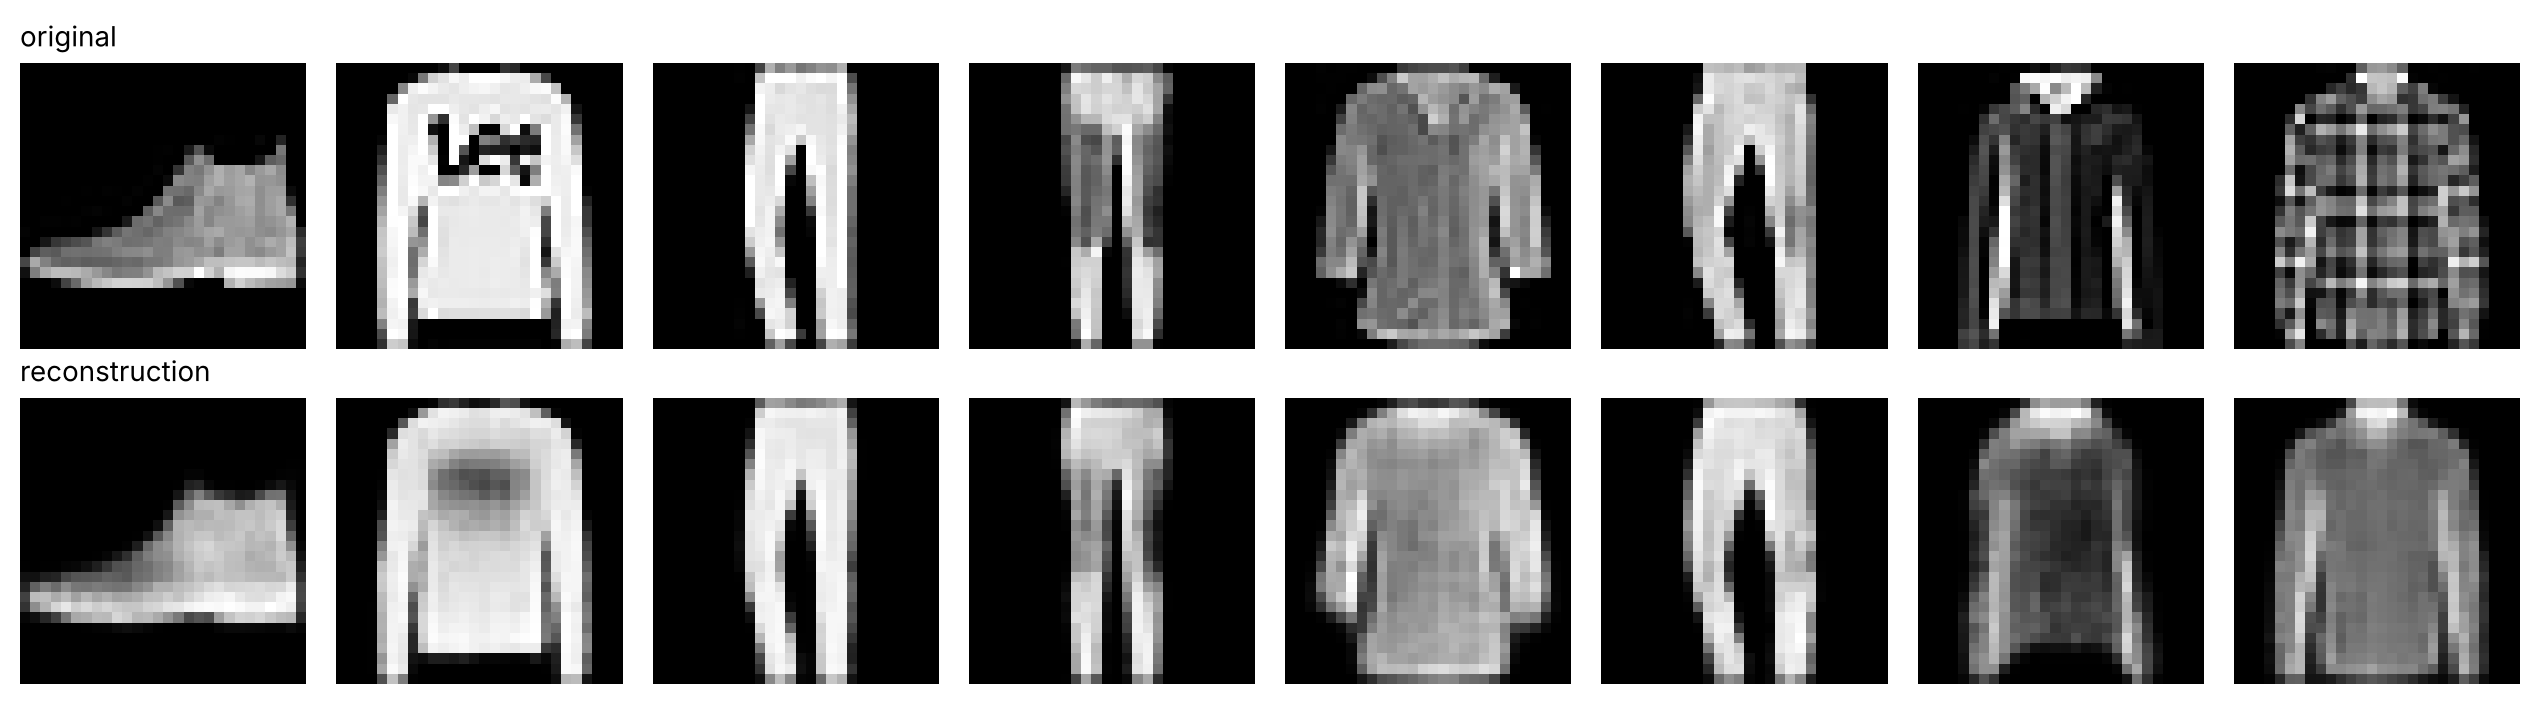

In [4]:
@torch.no_grad()
def show_reconstructions(model, noise_std=0.0, n=8):
    model.eval()
    x = next(iter(test_loader))[0][:n].to(device)
    inp = (x + noise_std * torch.randn_like(x)).clamp(0, 1) if noise_std > 0 else x
    out = model(inp)
    rows = [x, inp, out] if noise_std > 0 else [x, out]
    titles = ['original', 'noisy input', 'output'] if noise_std > 0 else ['original', 'reconstruction']
    fig, axes = plt.subplots(len(rows), n, figsize=(1.6 * n, 1.8 * len(rows)))
    for r, (row, title) in enumerate(zip(rows, titles)):
        for c in range(n):
            axes[r, c].imshow(row[c, 0].cpu(), cmap='gray'); axes[r, c].axis('off')
        axes[r, 0].set_title(title, fontsize=10, loc='left')
    plt.tight_layout(); plt.show()


show_reconstructions(ae)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

بازسازی‌ها شکل کلی را به‌خوبی حفظ کرده‌اند اما کمی **تار** هستند: ۱۶ عدد برای ذخیره همه جزئیات کافی نیست و Loss مربعی، میانگین حالت‌های ممکن را ترجیح می‌دهد.

### نمایش فضای نهان

فضای نهان ۱۶ بعدی را با **t-SNE** (از دوره یادگیری ماشین) به دو بعد می‌بریم. با اینکه مدل هیچ برچسبی ندیده، تصاویر هر کلاس کنار هم قرار گرفته‌اند:

</div>

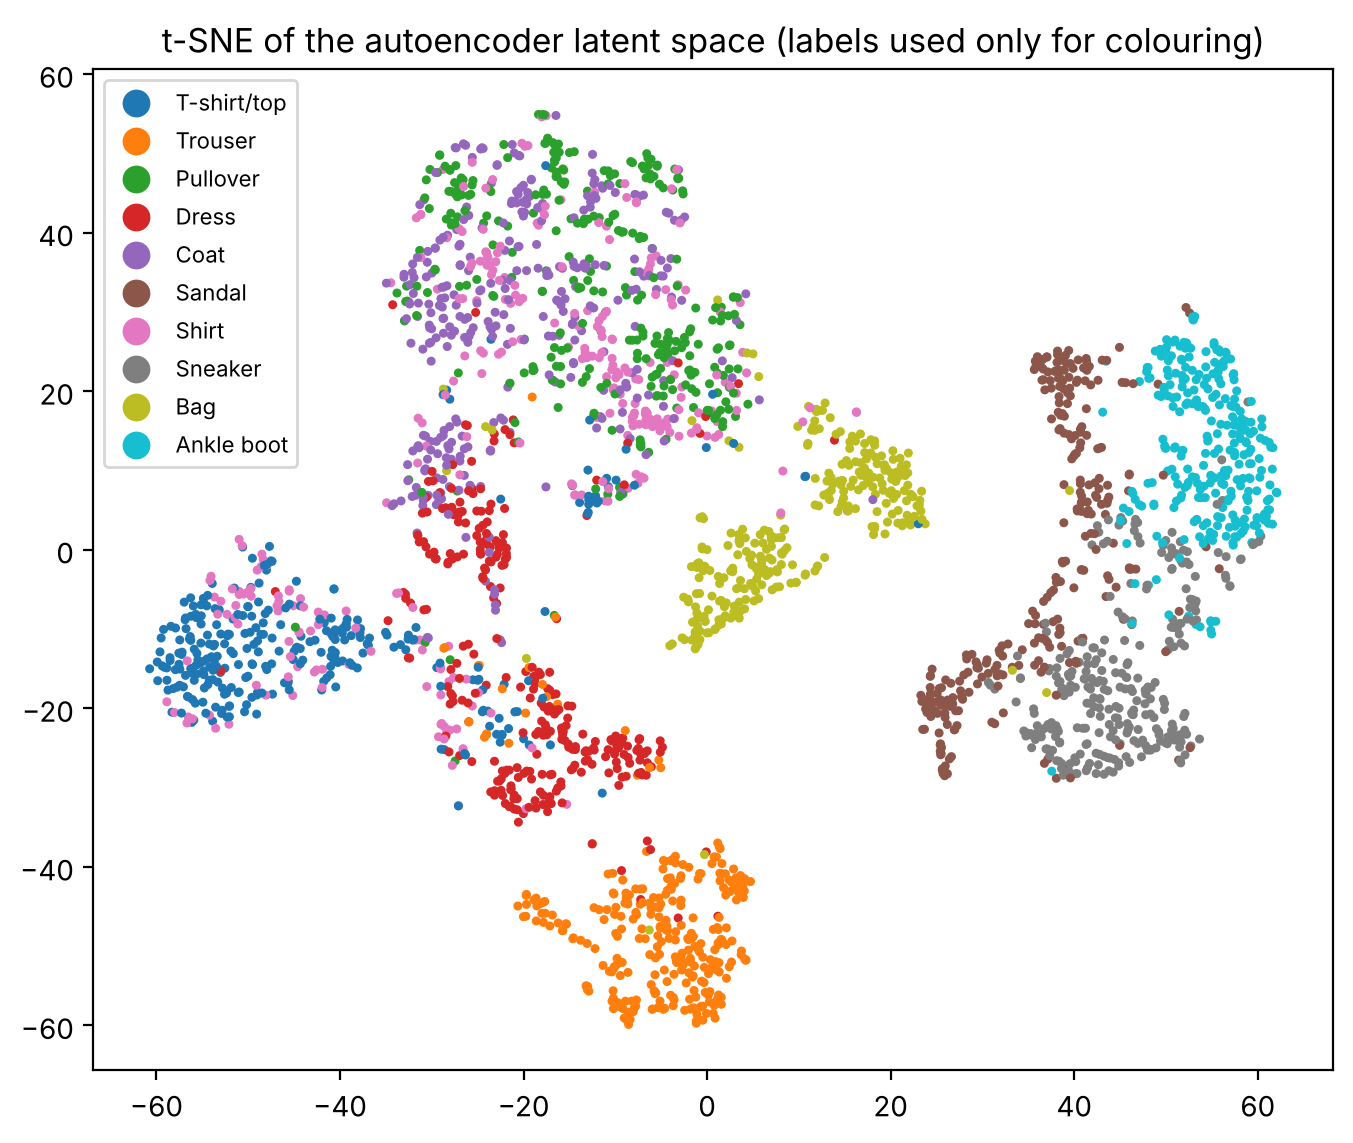

In [5]:
from sklearn.manifold import TSNE


@torch.no_grad()
def encode_all(encoder, n=3000):
    zs, ys = [], []
    for x, y in test_loader:
        zs.append(encoder(x.to(device)).cpu()); ys.append(y)
    return torch.cat(zs)[:n].numpy(), torch.cat(ys)[:n].numpy()


ae.eval()
Z, Y = encode_all(ae.encoder)
Z2 = TSNE(n_components=2, random_state=0, init='pca').fit_transform(Z)
plt.figure(figsize=(8, 6.5))
sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=Y, cmap='tab10', s=5)
plt.legend(handles=sc.legend_elements()[0], labels=CLASSES, fontsize=8, markerscale=1.5, loc='best')
plt.title('t-SNE of the autoencoder latent space (labels used only for colouring)'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. Denoising Autoencoder

اگر ورودی را عمداً **نویزی** کنیم و از شبکه بخواهیم نسخه **تمیز** را بازسازی کند، شبکه یاد می‌گیرد ساختار واقعی داده را از نویز جدا کند (Vincent et al., 2008). همین ایده (حذف تدریجی نویز) پایه مدل‌های **Diffusion** است که در جلسه بعد می‌بینیم.

</div>

epoch  1 | reconstruction MSE 0.03087


epoch  2 | reconstruction MSE 0.01653


epoch  3 | reconstruction MSE 0.01482


epoch  4 | reconstruction MSE 0.01399


epoch  5 | reconstruction MSE 0.01351


epoch  6 | reconstruction MSE 0.01312


epoch  7 | reconstruction MSE 0.01286


epoch  8 | reconstruction MSE 0.01265


epoch  9 | reconstruction MSE 0.01247


epoch 10 | reconstruction MSE 0.01232


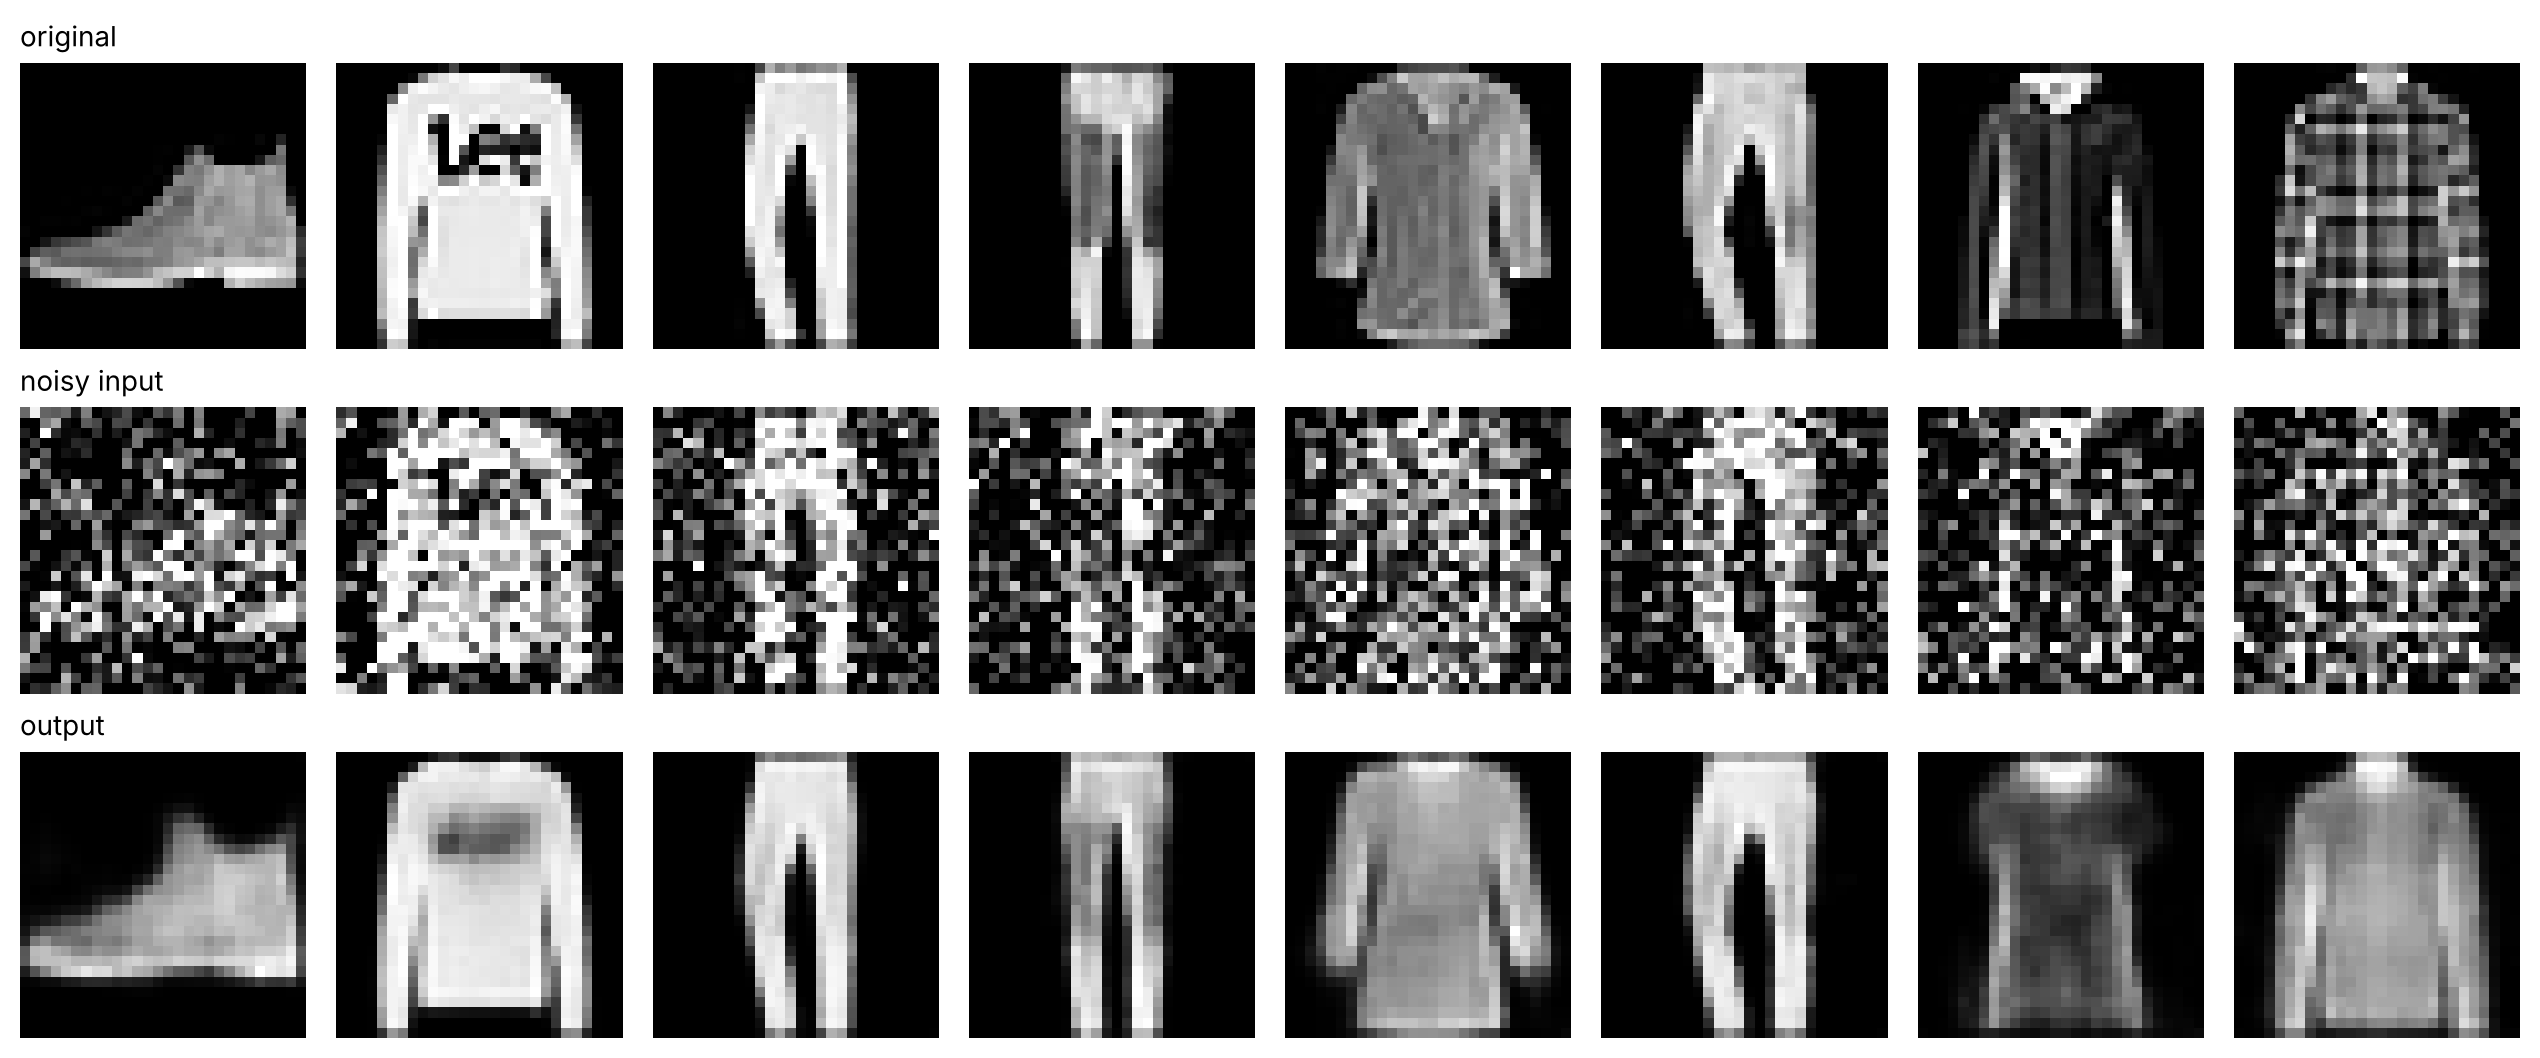

In [6]:
torch.manual_seed(0)
denoiser = train_autoencoder(Autoencoder(latent=32).to(device), EPOCHS, noise_std=0.4)
show_reconstructions(denoiser, noise_std=0.4)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. تشخیص ناهنجاری (Anomaly Detection)

Autoencoder داده‌هایی شبیه داده آموزشی را خوب بازسازی می‌کند و داده‌های **متفاوت** را بد. پس **خطای بازسازی** می‌تواند معیار ناهنجاری باشد؛ کاربردهای واقعی: تشخیص تقلب در تراکنش‌های بانکی، عیب‌یابی قطعات صنعتی و تشخیص نفوذ در شبکه.

آزمایش: یک Autoencoder را **فقط روی کفش‌ها** (Sandal، Sneaker، Ankle boot) آموزش می‌دهیم و خطای بازسازی کفش‌ها را با لباس‌ها مقایسه می‌کنیم:

</div>

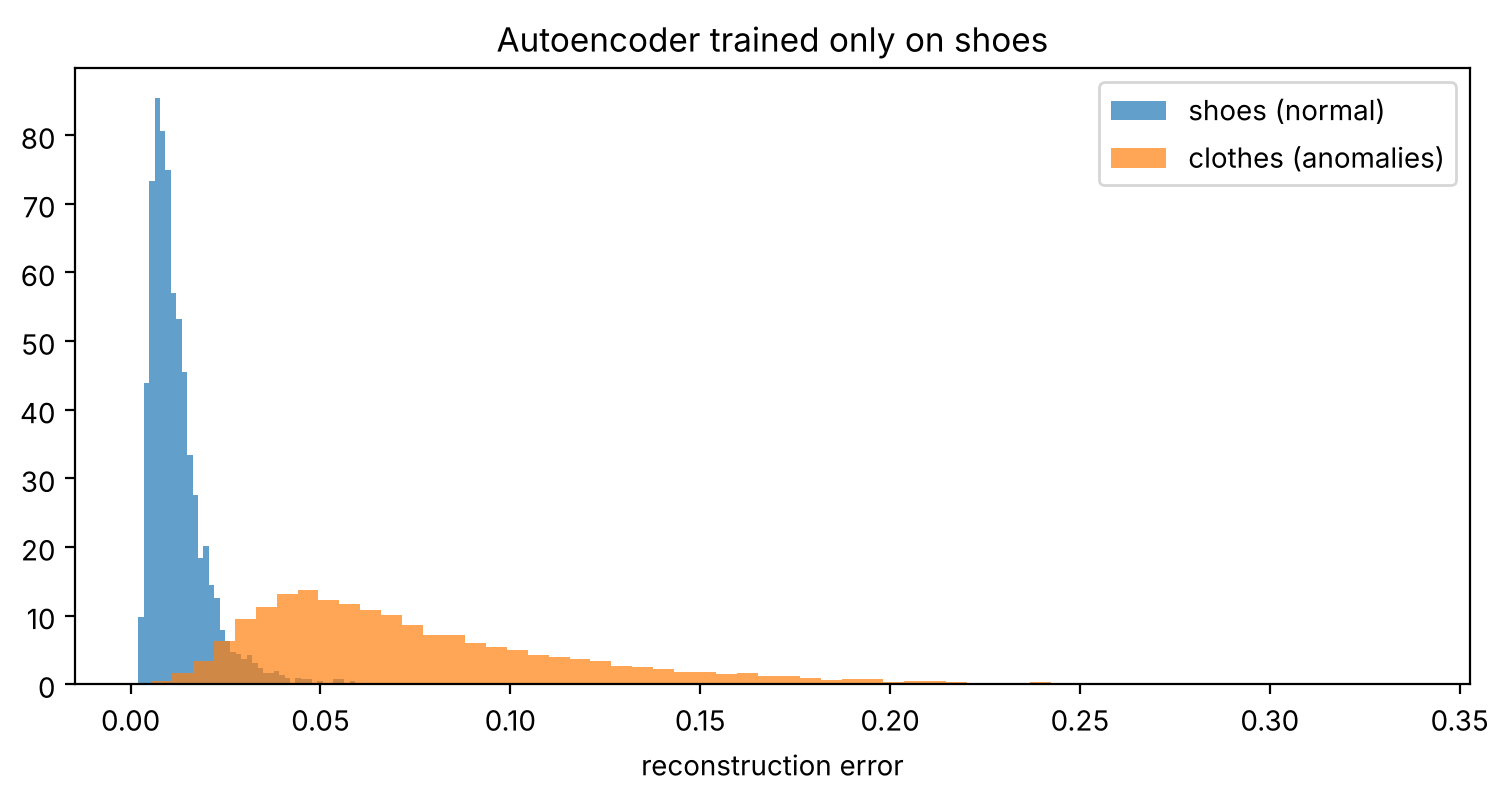

ROC-AUC of reconstruction error as an anomaly score: 0.987


In [7]:
from torch.utils.data import Subset

SHOES = [5, 7, 9]
shoe_idx = [i for i, y in enumerate(train_set.targets.tolist()) if y in SHOES]
shoe_loader = DataLoader(Subset(train_set, shoe_idx), batch_size=128, shuffle=True, num_workers=2)

torch.manual_seed(0)
shoe_ae = Autoencoder().to(device)
opt = torch.optim.Adam(shoe_ae.parameters(), lr=1e-3)
for epoch in range(EPOCHS):
    for x, _ in shoe_loader:
        x = x.to(device)
        loss = F.mse_loss(shoe_ae(x), x)
        opt.zero_grad(); loss.backward(); opt.step()


@torch.no_grad()
def reconstruction_errors(model):
    model.eval()
    errs, ys = [], []
    for x, y in test_loader:
        x = x.to(device)
        errs.append(((model(x) - x) ** 2).mean(dim=(1, 2, 3)).cpu()); ys.append(y)
    return torch.cat(errs).numpy(), torch.cat(ys).numpy()


err, y = reconstruction_errors(shoe_ae)
is_shoe = np.isin(y, SHOES)
plt.figure(figsize=(9, 4))
plt.hist(err[is_shoe], bins=60, alpha=0.7, density=True, label='shoes (normal)')
plt.hist(err[~is_shoe], bins=60, alpha=0.7, density=True, label='clothes (anomalies)')
plt.xlabel('reconstruction error'); plt.legend(); plt.title('Autoencoder trained only on shoes'); plt.show()

from sklearn.metrics import roc_auc_score
print(f'ROC-AUC of reconstruction error as an anomaly score: {roc_auc_score(~is_shoe, err):.3f}')

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. Variational Autoencoder (VAE)

آیا می‌توانیم با Decoder یک Autoencoder تصویر **جدید** تولید کنیم؟ کافی است یک $\mathbf{z}$ تصادفی به آن بدهیم؟ مشکل اینجاست که فضای نهان Autoencoder معمولی **نامنظم** است: کدهای داده واقعی در نواحی پراکنده‌ای قرار دارند و $\mathbf{z}$ تصادفی به احتمال زیاد در ناحیه‌ای «بی‌معنی» می‌افتد.

**VAE** (Kingma & Welling, 2014) فضای نهان را **منظم** می‌کند:

۱. Encoder به‌جای یک نقطه، یک **توزیع** گاوسی برمی‌گرداند: میانگین $\boldsymbol{\mu}$ و لگاریتم واریانس $\log\boldsymbol{\sigma}^2$.

۲. $\mathbf{z}$ از این توزیع **نمونه‌برداری** می‌شود و به Decoder می‌رود.

۳. Loss دو جمله دارد:

$$\mathcal{L} = \underbrace{\text{Reconstruction}(\mathbf{x}, \hat{\mathbf{x}})}_{\text{بازسازی خوب}} + \beta\cdot\underbrace{D_{KL}\left(\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma}^2)\,\|\,\mathcal{N}(\mathbf{0}, I)\right)}_{\text{نزدیک بودن به توزیع استاندارد}}$$

جمله **KL Divergence** توزیع هر نمونه را به سمت گاوسی استاندارد می‌کشد؛ پس کدها کل فضا را به‌صورت پیوسته پر می‌کنند و بعداً می‌توانیم با نمونه‌برداری از $\mathcal{N}(\mathbf{0}, I)$ تصویر جدید بسازیم. برای دو گاوسی، KL فرم بسته دارد:

$$D_{KL} = -\frac{1}{2}\sum_{j}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

### ترفند Reparameterization

نمونه‌برداری تصادفی مشتق‌پذیر نیست و گرادیان از آن عبور نمی‌کند. راه‌حل: تصادفی بودن را به یک متغیر مستقل منتقل می‌کنیم:

$$\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma}\odot\boldsymbol{\epsilon},\qquad \boldsymbol{\epsilon}\sim\mathcal{N}(\mathbf{0}, I)$$

حالا $\mathbf{z}$ تابعی مشتق‌پذیر از $\boldsymbol{\mu}$ و $\boldsymbol{\sigma}$ است و Backpropagation کار می‌کند.

</div>

In [8]:
class VAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.latent = latent
        self.encoder = Encoder(latent, out_mult=2)        # outputs [mu, log_var]
        self.decoder = Decoder(latent)

    def encode(self, x):
        mu, log_var = self.encoder(x).chunk(2, dim=1)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        return mu + std * torch.randn_like(std)           # z = mu + sigma * epsilon

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        return self.decoder(z), mu, log_var


def vae_loss(x_hat, x, mu, log_var, beta=1.0):
    recon = F.binary_cross_entropy(x_hat, x, reduction='sum') / len(x)          # per image
    kl = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / len(x)
    return recon + beta * kl, recon, kl


torch.manual_seed(0)
vae = VAE().to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
VAE_EPOCHS = 15
for epoch in range(1, VAE_EPOCHS + 1):
    vae.train()
    tot = rec = kld = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, mu, log_var = vae(x)
        loss, r, k = vae_loss(x_hat, x, mu, log_var)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(x); rec += r.item() * len(x); kld += k.item() * len(x)
    n = len(train_set)
    print(f'epoch {epoch:2d} | loss {tot / n:7.2f} = reconstruction {rec / n:7.2f} + KL {kld / n:5.2f}')

epoch  1 | loss  289.64 = reconstruction  273.77 + KL 15.88


epoch  2 | loss  251.79 = reconstruction  234.61 + KL 17.17


epoch  3 | loss  247.50 = reconstruction  230.18 + KL 17.32


epoch  4 | loss  245.48 = reconstruction  228.07 + KL 17.41


epoch  5 | loss  244.25 = reconstruction  226.81 + KL 17.44


epoch  6 | loss  243.39 = reconstruction  225.94 + KL 17.45


... (5 outputs left out)

epoch 12 | loss  240.73 = reconstruction  223.38 + KL 17.35


epoch 13 | loss  240.45 = reconstruction  223.12 + KL 17.33


epoch 14 | loss  240.25 = reconstruction  222.90 + KL 17.35


epoch 15 | loss  240.04 = reconstruction  222.75 + KL 17.30


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برای تصاویر با پیکسل‌های بین صفر و یک، Binary Cross-Entropy (BCE) به‌عنوان خطای بازسازی رایج است. هر دو جمله برای **یک تصویر** جمع زده شده‌اند تا وزن نسبی آن‌ها معنادار باشد.

### تولید تصاویر جدید

حالا از توزیع استاندارد نمونه می‌گیریم و فقط Decoder را اجرا می‌کنیم. این تصاویر در داده آموزشی وجود ندارند:

</div>

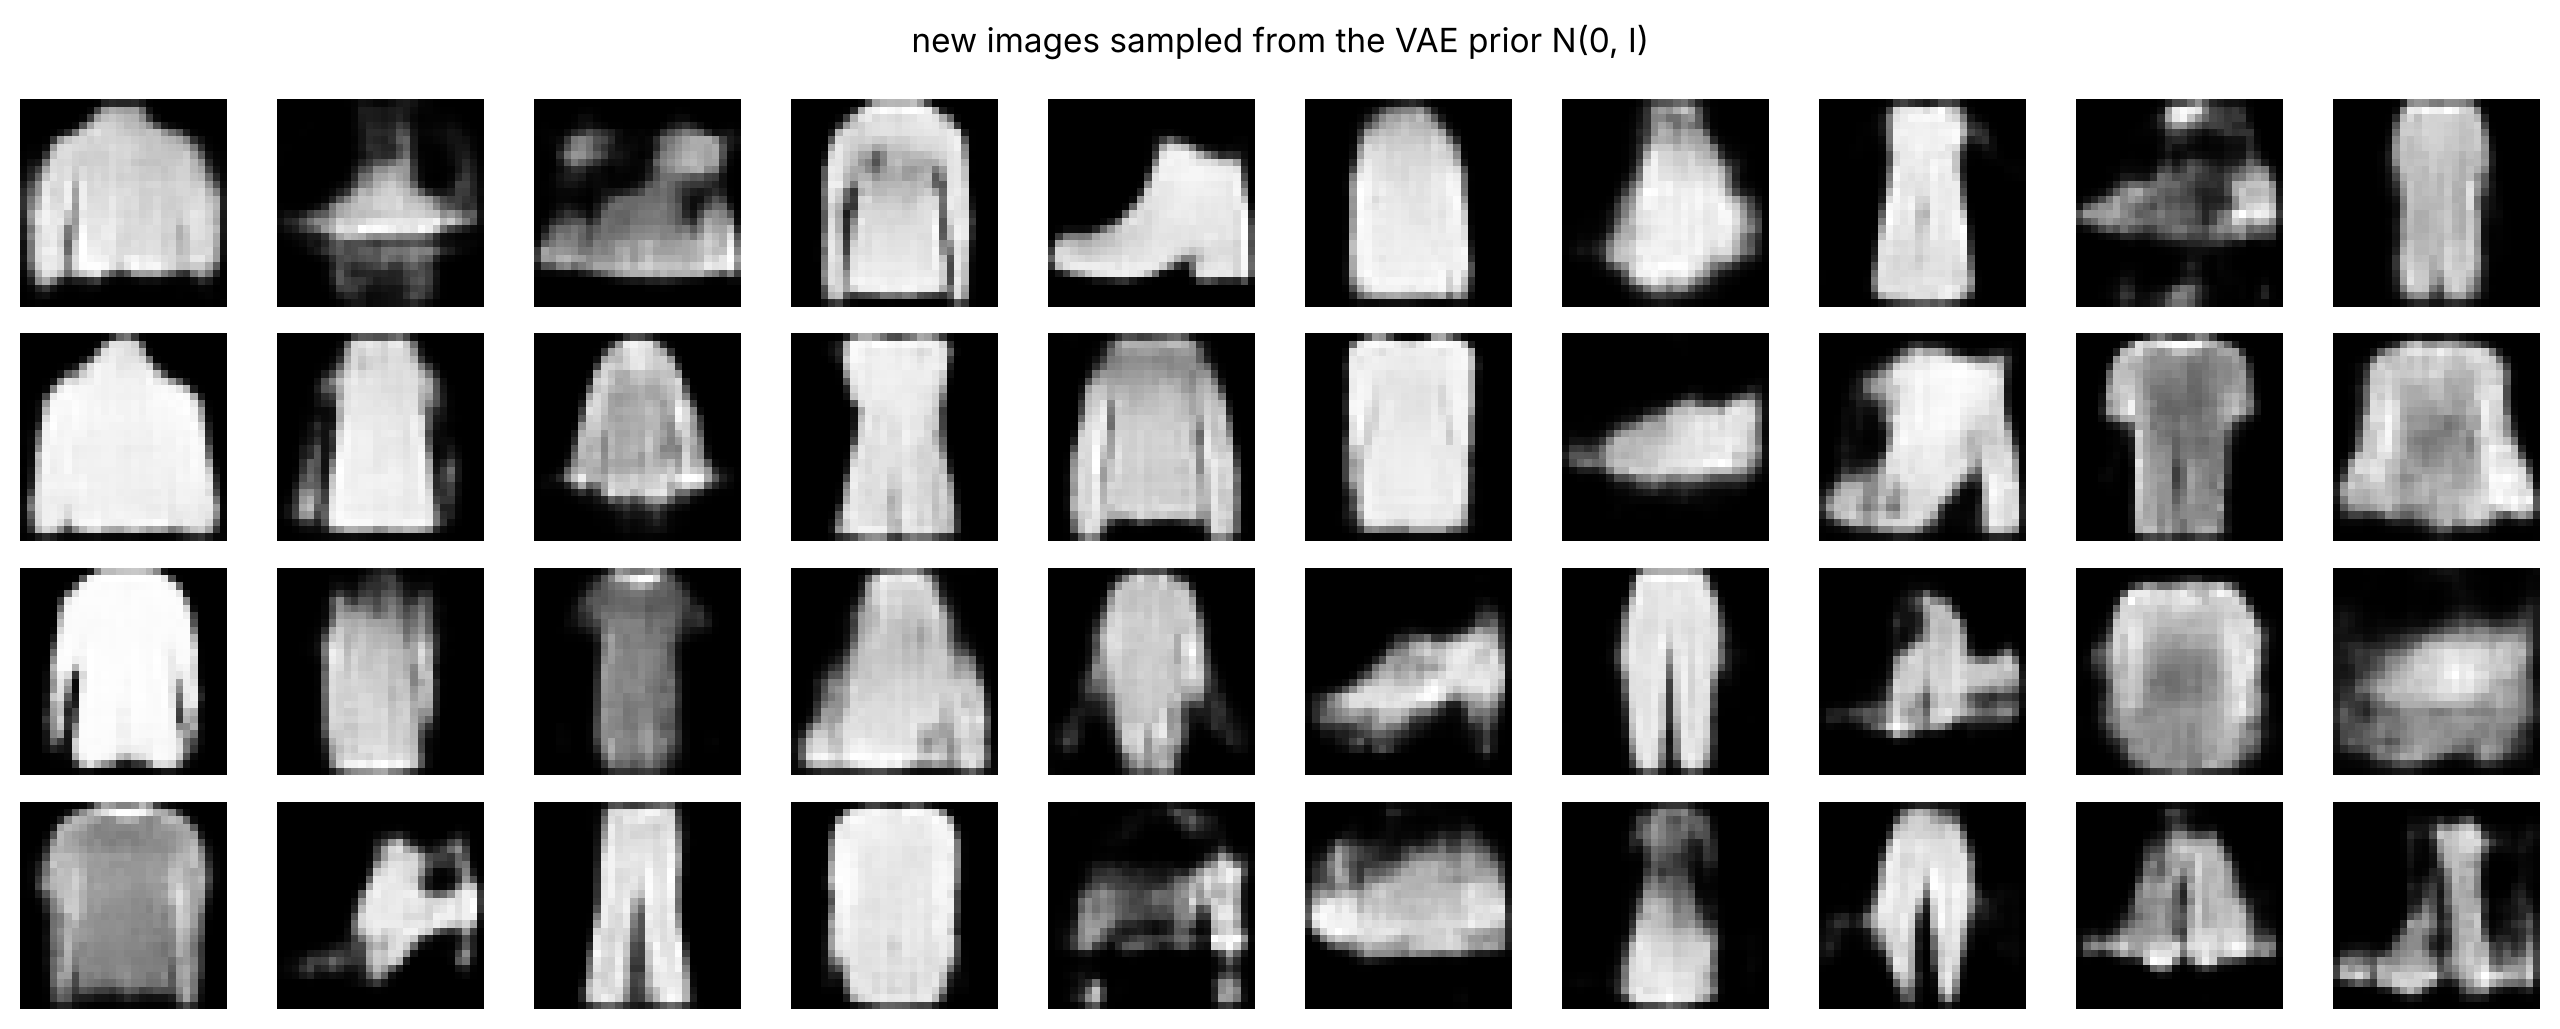

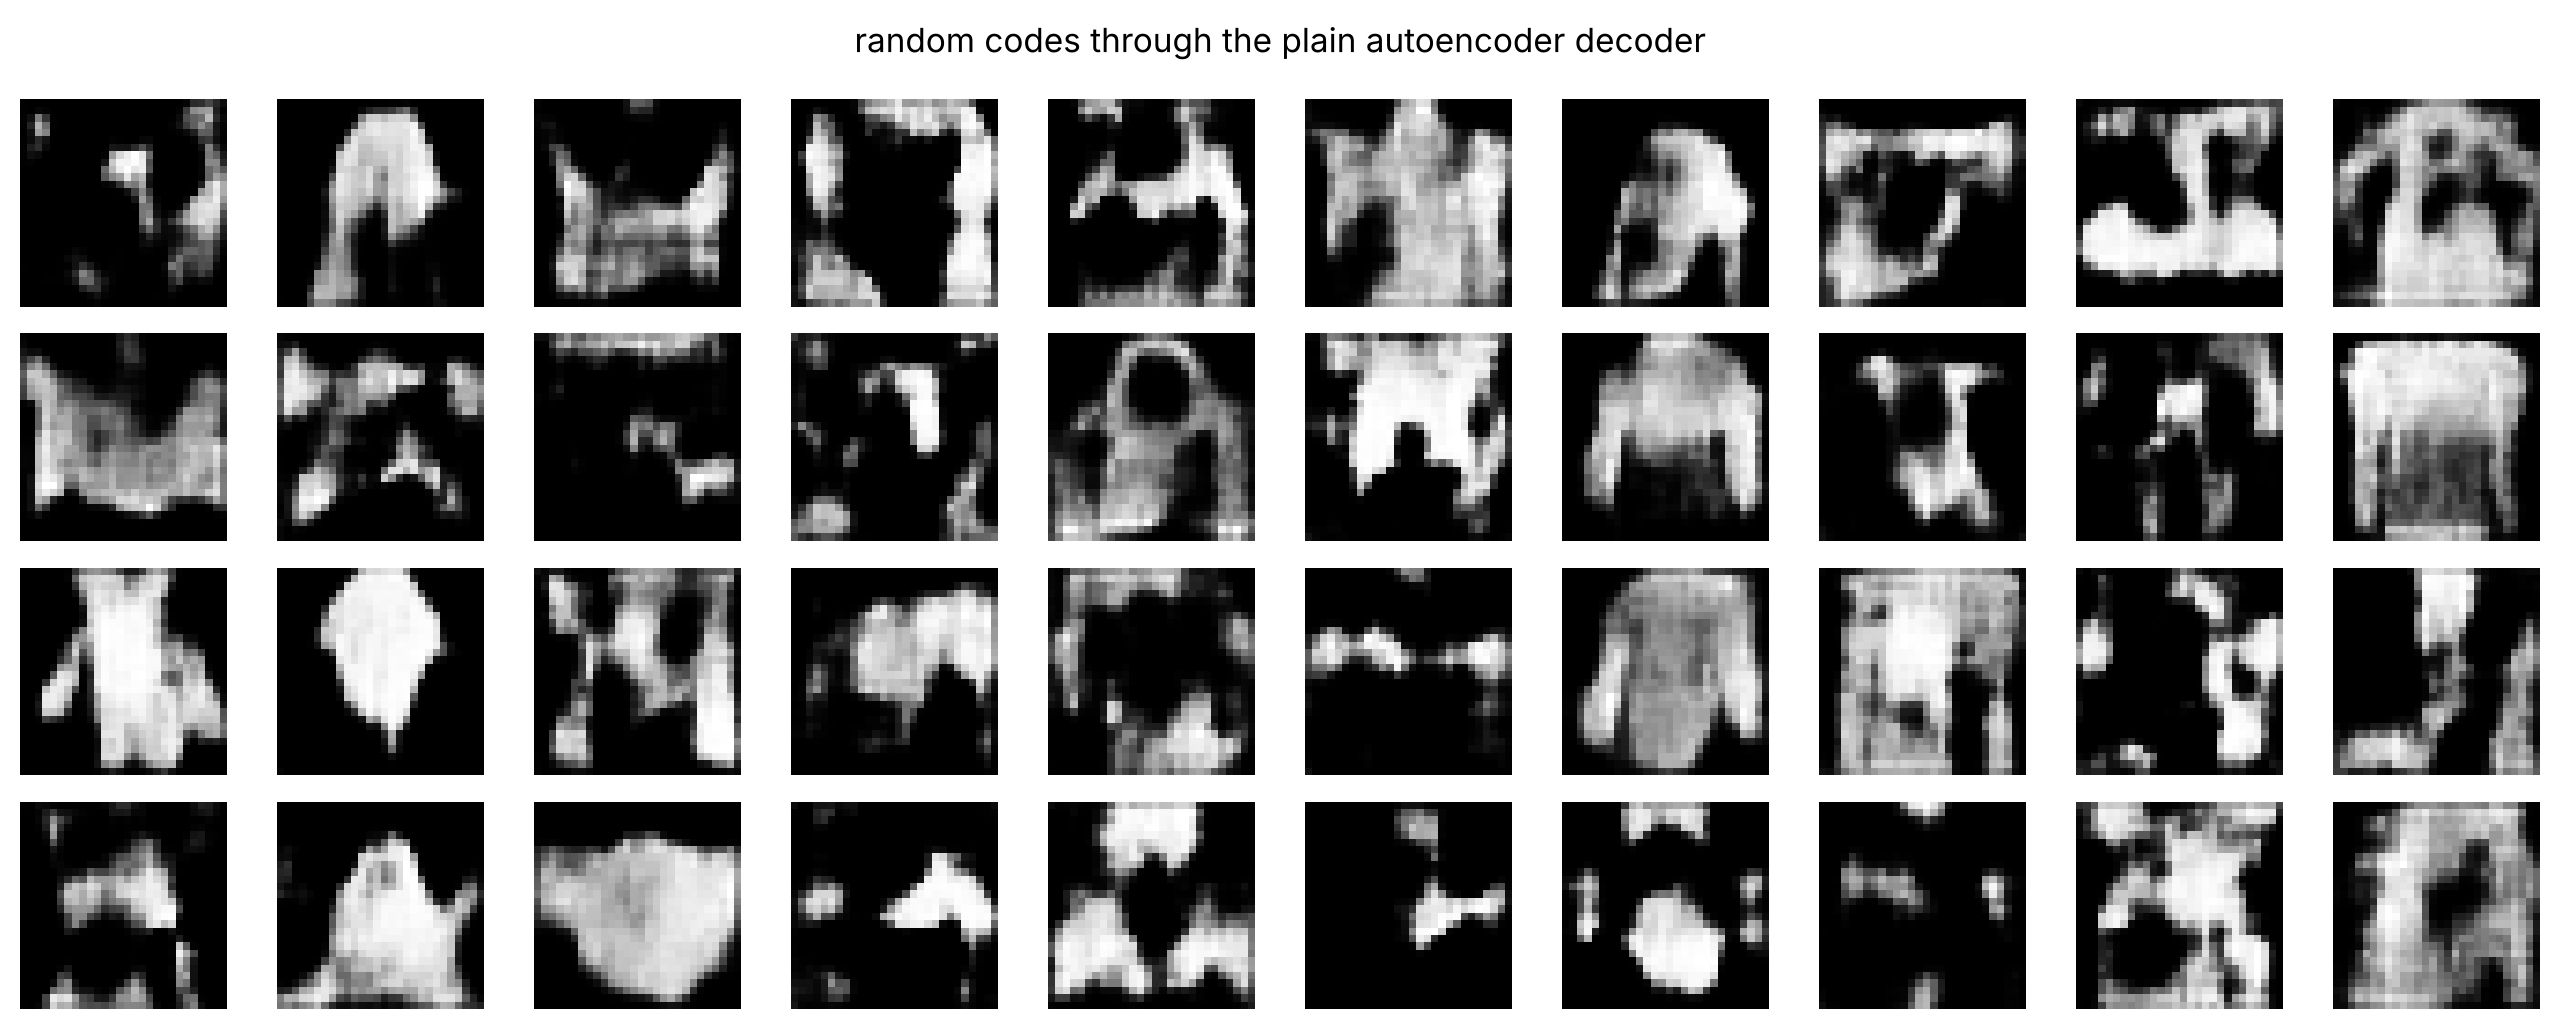

In [9]:
@torch.no_grad()
def show_grid(images, nrow, title):
    images = images.cpu()
    ncol = len(images) // nrow
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.3 * ncol, 1.3 * nrow))
    for ax, img in zip(axes.flat, images):
        ax.imshow(img[0], cmap='gray'); ax.axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.show()


vae.eval()
with torch.no_grad():
    z = torch.randn(40, LATENT, device=device)
    show_grid(vae.decoder(z), 4, 'new images sampled from the VAE prior N(0, I)')

    # the same experiment with the plain autoencoder decoder
    z_ae = torch.randn(40, LATENT, device=device) * ae.encoder(next(iter(test_loader))[0].to(device)).std()
    show_grid(ae.decoder(z_ae), 4, 'random codes through the plain autoencoder decoder')

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نمونه‌های VAE شبیه لباس و کفش واقعی‌اند (هرچند کمی تار)، اما کدهای تصادفی در Autoencoder معمولی اغلب تصاویر نامفهوم تولید می‌کنند؛ این همان اثر منظم‌سازی فضای نهان است.

### درون‌یابی در فضای نهان

چون فضای نهان VAE پیوسته است، حرکت روی خط راست بین کد دو تصویر، تبدیلی نرم و معنادار بین آن‌ها می‌سازد:

</div>

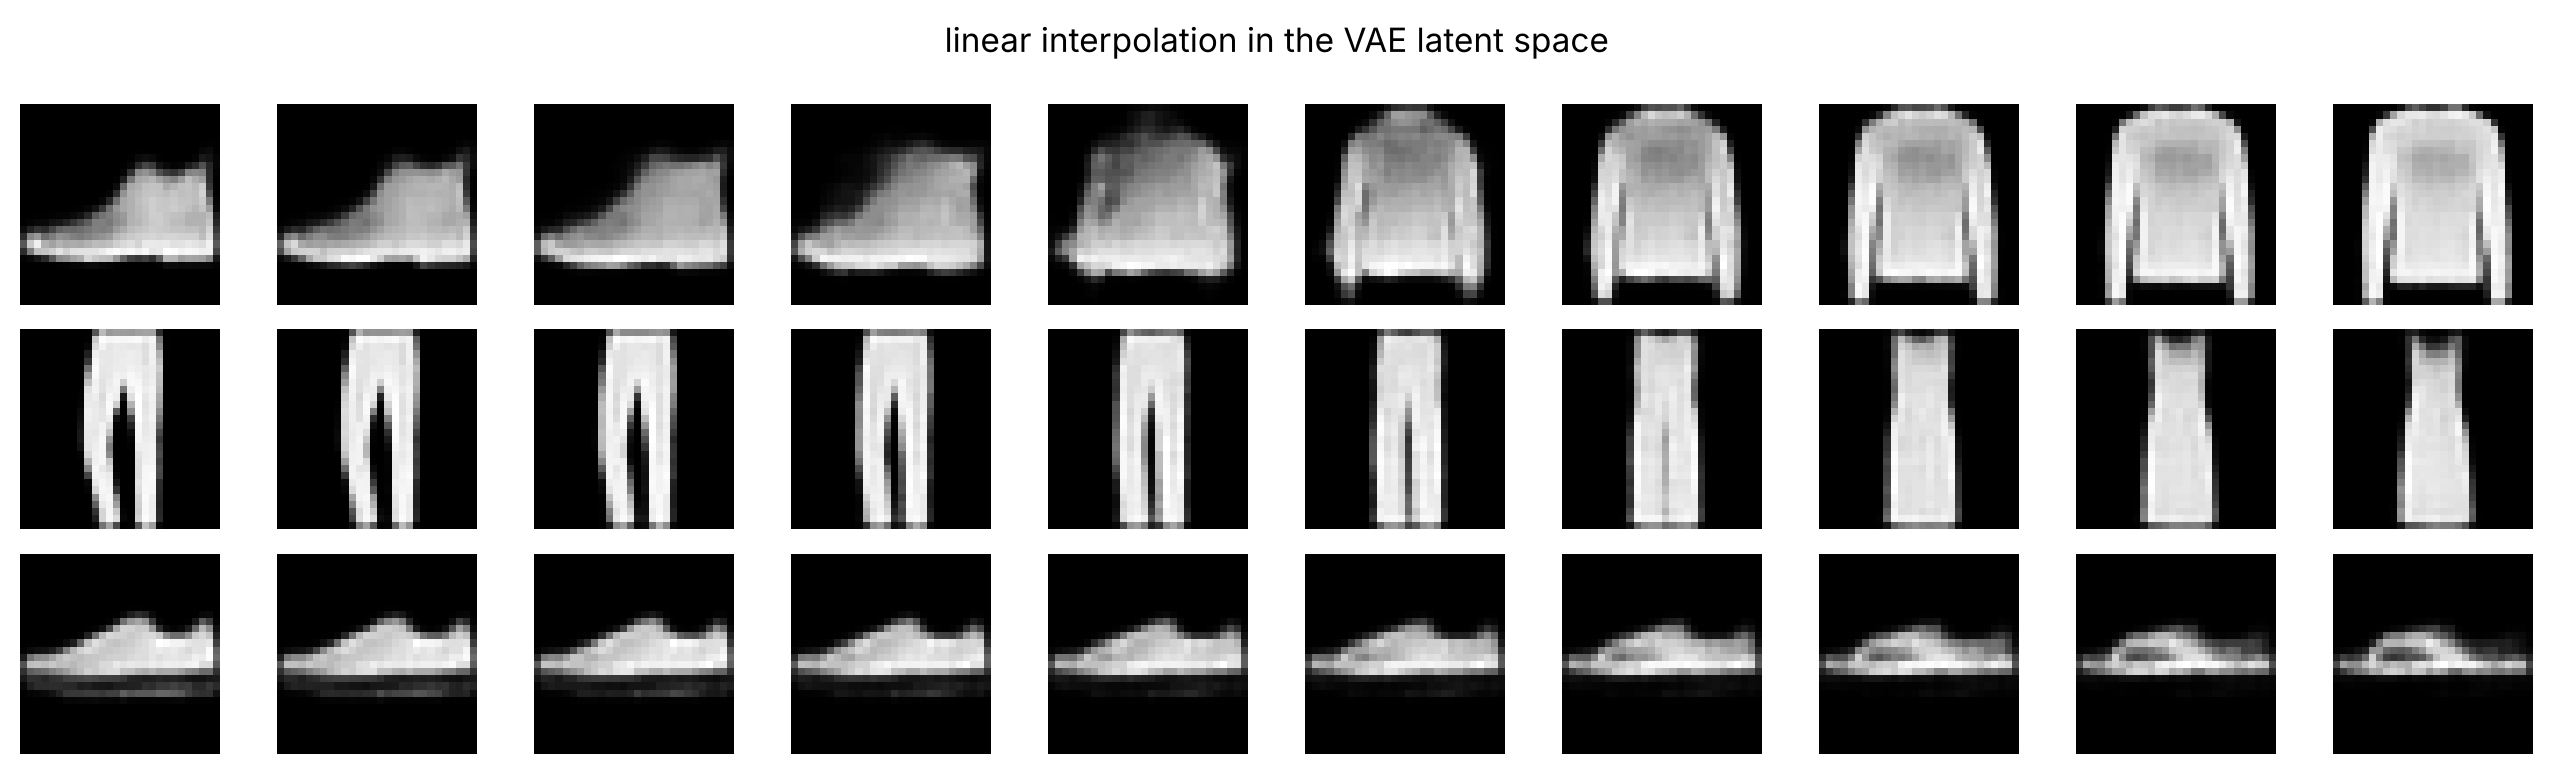

In [10]:
@torch.no_grad()
def interpolate(model, img_a, img_b, steps=10):
    mu_a, _ = model.encode(img_a.unsqueeze(0).to(device))
    mu_b, _ = model.encode(img_b.unsqueeze(0).to(device))
    alphas = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    return model.decoder((1 - alphas) * mu_a + alphas * mu_b)


pairs = [(test_set[0][0], test_set[1][0]), (test_set[2][0], test_set[13][0]), (test_set[9][0], test_set[8][0])]
rows = torch.cat([interpolate(vae, a, b) for a, b in pairs])
show_grid(rows, len(pairs), 'linear interpolation in the VAE latent space')

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

VAEها پایه بسیاری از مدل‌های مولد مدرن‌اند؛ برای مثال **Stable Diffusion** فرایند Diffusion را نه روی پیکسل‌ها، بلکه در فضای نهان یک Autoencoder انجام می‌دهد (Latent Diffusion) تا محاسبات بسیار کمتر شود.

## جمع‌بندی

- Autoencoder با بازسازی ورودی از یک گلوگاه کوچک، بدون برچسب ساختار داده را یاد می‌گیرد.
- `ConvTranspose2d` در Decoder ابعاد مکانی را افزایش می‌دهد.
- Denoising Autoencoder: ورودی نویزی، هدف تمیز. خطای بازسازی معیار خوبی برای تشخیص ناهنجاری است.
- VAE: Encoder یک توزیع ($\boldsymbol{\mu}, \boldsymbol{\sigma}$) برمی‌گرداند؛ Loss = بازسازی + KL.
- ترفند Reparameterization، $\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma}\odot\boldsymbol{\epsilon}$، نمونه‌برداری را مشتق‌پذیر می‌کند.
- فضای نهان منظم VAE امکان تولید نمونه جدید و درون‌یابی معنادار را می‌دهد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. Autoencoder را با `LATENT` برابر ۲، ۸ و ۶۴ آموزش دهید و خطای بازسازی و کیفیت تصاویر را مقایسه کنید.

۲. یک VAE با فضای نهان **دوبعدی** آموزش دهید و Decoder را روی یک شبکه منظم از نقاط در بازه $[-3, 3]^2$ اجرا کنید تا «نقشه» کامل فضای نهان را ببینید.

۳. **β-VAE:** VAE را با $\beta = 0.1$ و $\beta = 4$ آموزش دهید. کیفیت بازسازی و کیفیت نمونه‌های تولیدی چه تغییری می‌کند؟ چرا؟

۴. در تشخیص ناهنجاری، Autoencoder را فقط روی یک کلاس (مثلاً Trouser) آموزش دهید و ROC-AUC را برای تشخیص بقیه کلاس‌ها حساب کنید.

۵. Denoising Autoencoder را برای نوع دیگری از خرابی آموزش دهید: پاک کردن یک مربع ۱۰×۱۰ تصادفی از تصویر (**Inpainting**).

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** Autoencoder را با `LATENT` برابر ۲، ۸ و ۶۴ آموزش دهید و خطای بازسازی و کیفیت تصاویر را مقایسه کنید.

</div>

In [11]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** یک VAE با فضای نهان **دوبعدی** آموزش دهید و Decoder را روی یک شبکه منظم از نقاط در بازه $[-3, 3]^2$ اجرا کنید تا «نقشه» کامل فضای نهان را ببینید.

</div>

In [12]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** **β-VAE:** VAE را با $\beta = 0.1$ و $\beta = 4$ آموزش دهید. کیفیت بازسازی و کیفیت نمونه‌های تولیدی چه تغییری می‌کند؟ چرا؟

</div>

In [13]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** در تشخیص ناهنجاری، Autoencoder را فقط روی یک کلاس (مثلاً Trouser) آموزش دهید و ROC-AUC را برای تشخیص بقیه کلاس‌ها حساب کنید.

</div>

In [14]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** Denoising Autoencoder را برای نوع دیگری از خرابی آموزش دهید: پاک کردن یک مربع ۱۰×۱۰ تصادفی از تصویر (**Inpainting**).

</div>

In [15]:
# پاسخ خود را اینجا بنویسید
